In [ ]:
import os
import glob
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

def calc_geometric_transit_probability(df):
    # Cross-match with CTL.csv to add stellar mass
    ctl_df = pd.read_csv('./take_two_stellar_params_CTL.csv')
    df = df.copy()

    # Clean TIC column in both dataframes to ensure matching
    df['TIC_clean'] = df['TIC'].str.replace('TIC ', '')
    ctl_df['TIC_clean'] = ctl_df['id'].astype(str).str.replace('TIC ', '')

    # Merge to add stellar mass
    df = df.merge(
        ctl_df[['TIC_clean', 'MASS']], 
        on='TIC_clean', 
        how='left'
    ).rename(columns={'MASS': 'Stellar Mass'})

    # Drop the temporary TIC_clean column
    df = df.drop('TIC_clean', axis=1)

    # Check for missing stellar masses and remove them
    missing_mass = df['Stellar Mass'].isna().sum()
    print(f"Removing {missing_mass} rows with missing stellar mass")
    df = df.dropna(subset=['Stellar Mass'])
    print(f"Dataframe size after removal: {len(df)} rows")

    # Calculate transit probability using actual stellar mass (vectorized)
    R_star = df['Stellar Radius'] * 6.96e8  # Solar radii to meters
    R_planet = df['True Radius (Earth Radii)'] * 6.371e6  # Earth radii to meters
    P = df['True Period (Days)'] * 86400  # Days to seconds
    M_star = df['Stellar Mass'] * 1.989e30  # Solar masses to kg
    G = 6.67430e-11  # Gravitational constant in m³/(kg·s²)

    a = ((P**2 * G * M_star) / (4 * np.pi**2))**(1/3)  # Semi-major axis in meters
    df['Transit Probability'] = (R_star + R_planet) / a

    return df

def filter_out_false_positives(df, sde_threshold):
    false_positive_df = pd.read_csv('/Users/danayaptangco/local_code/Mulders/main_proj/tess_demographics/gen_heatmaps/rec_only/rec_results/take_two_CTL_TLS_recovery.csv')

    rows_to_keep = []
    false_positive_count = 0

    for idx, row in df.iterrows():
        tic = row['TIC']
        true_period = float(row['True Period (Days)'])
        
        # Check if this TIC exists in false positives data
        fp_row = false_positive_df[false_positive_df['TIC'] == tic]
        
        is_false_positive = False
        
        # If we found matching TIC in false positive data
        if len(fp_row) > 0:
            try:
                # Parse false positive periods and SDE arrays
                fp_periods = fp_row['TLS Periods array'].iloc[0].replace('[', '').replace(']', '').split()
                fp_periods = [float(p) for p in fp_periods]
                fp_sde = fp_row['TLS SDE > 7 array'].iloc[0].replace('[', '').replace(']', '').split()
                fp_sde = [float(s) for s in fp_sde]
                
                # Get periods above threshold from false positives
                fp_periods_above_threshold = [p for p, s in zip(fp_periods, fp_sde) if s > sde_threshold]
                
                # Check if any false positive periods match our true period or its aliases
                aliases = [true_period, true_period/2, true_period*2, true_period/3, true_period*3]
                is_false_positive = any(0.999 * alias < fp_p < 1.001 * alias 
                                    for fp_p in fp_periods_above_threshold 
                                    for alias in aliases)

                # SET TO 0 method
                if any(any(0.999 * alias < fp_p < 1.001 * alias for alias in aliases) for fp_p in fp_periods_above_threshold):
                    df.loc[idx, 'TLS Periods array'] = '[]'
                    df.loc[idx, 'TLS SDE > 7 array'] = '[]'
                    false_positive_count += 1
            except:
                pass
        
        # Keep the row only if it's NOT a false positive
        if is_false_positive == False:
            rows_to_keep.append(idx)
        # SET TO 0 method
        elif is_false_positive == True:
            rows_to_keep.append(idx)

    # Filter the dataframe
    df_filtered = df.loc[rows_to_keep].reset_index(drop=True)
    print(f"False positive cells removed: {false_positive_count}")

    return df_filtered

def individual_tic_heatmaps(df, sde_threshold, temp_range, periods_bins, radii_bins):
    """
    Generate individual heatmaps for each TIC within a temperature range.
    
    Parameters:
    df: DataFrame with TIC data
    sde_threshold: SDE threshold for detection
    temp_range: tuple (temp_min, temp_max) for stellar temperature filtering
    periods_bins: list of (min, max) tuples for period bins
    radii_bins: list of (min, max) tuples for radius bins
    """
    temp_min, temp_max = temp_range
    
    # Filter based on Stellar Temperature
    temp_lim = (df['Stellar Temperature'] >= temp_min) & (df['Stellar Temperature'] <= temp_max)
    df = df[temp_lim].copy()
    
    # Add geometric transit probability and filter false positives
    df = calc_geometric_transit_probability(df)
    df = filter_out_false_positives(df, sde_threshold)
    
    unique_tics = df['TIC'].unique()
    print(f"Processing {len(unique_tics)} unique TICs in temperature range {temp_min}-{temp_max} K")

    # Calculate bin centers for labeling
    radius_centers = [10**((np.log10(rmin) + np.log10(rmax))/2) for rmin, rmax in radii_bins]
    period_centers = [10**((np.log10(pmin) + np.log10(pmax))/2) for pmin, pmax in periods_bins]

    for tic in unique_tics:
        try:
            # Get all rows for this TIC
            tic_df = pd.DataFrame(columns=['TIC', 'True Radius (Earth Radii)', 'True Period (Days)', 
                                         'Detection', '# trials', 'TLS Periods array', 'TLS SDE > 7 array'])
            tic_rows = df[df['TIC'] == tic]
            
            if tic_rows['True Radius (Earth Radii)'].isnull().all():
                print(f"No valid data for {tic}, skipping...")
                continue
                
            for idx, row in tic_rows.iterrows():
                tic_df = pd.concat([tic_df, pd.DataFrame({
                    'TIC': [tic],
                    'True Radius (Earth Radii)': [row['True Radius (Earth Radii)']],
                    'True Period (Days)': [row['True Period (Days)']],
                    'Detection': [row['Detection']],
                    '# trials': [row['# trials']],
                    'TLS Periods array': [row['TLS Periods array']],
                    'TLS SDE > 7 array': [row['TLS SDE > 7 array']]
                })], ignore_index=True)

            # Create heatmap for this TIC
            heatmap_df = pd.DataFrame(columns=['radius_bin_center', 'period_bin_center', 'Detection'])
            
            for index, row in tic_df.iterrows():
                true_period = float(row['True Period (Days)'])
                true_radius = float(row['True Radius (Earth Radii)'])
                
                # Find which bin this period and radius fall into
                period_bin_center = None
                for i, (pmin, pmax) in enumerate(periods_bins):
                    if pmin <= true_period < pmax:
                        period_bin_center = period_centers[i]
                        break
                
                radius_bin_center = None
                for i, (rmin, rmax) in enumerate(radii_bins):
                    if rmin <= true_radius < rmax:
                        radius_bin_center = radius_centers[i]
                        break
                
                # Skip if outside bin ranges
                if period_bin_center is None or radius_bin_center is None:
                    continue
                
                periods = row['TLS Periods array']
                try:
                    periods = periods.replace('[', '').replace(']', '').split()
                except:
                    continue
                periods = [float(p) for p in periods]
                
                sde = row['TLS SDE > 7 array']
                try:
                    sde = sde.replace('[', '').replace(']', '').split()
                except:
                    continue
                sde = [float(s) for s in sde]
                
                periods_sde_tuple = zip(periods, sde)
                periods_above_threshold = np.array([], dtype=float)
                
                for periods_val, sde_val in periods_sde_tuple:
                    if sde_val > sde_threshold:
                        periods_above_threshold = np.append(periods_above_threshold, periods_val)
                
                # Check if true_period is close to any period above threshold (within 1% relative difference)
                aliases = [true_period, true_period / 2, true_period * 2, true_period / 3, true_period * 3]
                
                if any(0.999 * alias < hp < 1.001 * alias for hp in periods_above_threshold for alias in aliases):
                    detection = 1
                else:
                    detection = 0
                    
                heatmap_df = pd.concat([heatmap_df, pd.DataFrame({
                    'radius_bin_center': [radius_bin_center],
                    'period_bin_center': [period_bin_center],
                    'Detection': [detection] 
                })], ignore_index=True)

            # Convert Detection column to numeric for averaging
            heatmap_df['Detection'] = pd.to_numeric(heatmap_df['Detection'])
            
            # Group by bin centers, counting detections and total trials
            heatmap_counts = heatmap_df.groupby(['radius_bin_center', 'period_bin_center']).agg(
                detections=('Detection', 'sum'),
                trials=('Detection', 'count')
            ).reset_index()

            # Numeric detection rate for coloring
            heatmap_counts['detection_rate'] = heatmap_counts['detections'] / heatmap_counts['trials']

            # Pivot for heatmap coloring
            heatmap_pivot = heatmap_counts.pivot(
                index='radius_bin_center',
                columns='period_bin_center',
                values='detection_rate'
            )

            # Create annotation matrix with "detections/trials" strings
            annot_matrix = heatmap_counts.pivot(
                index='radius_bin_center',
                columns='period_bin_center',
                values='detections'
            ).astype(str) + "/" + heatmap_counts.pivot(
                index='radius_bin_center',
                columns='period_bin_center',
                values='trials'
            ).astype(str)

            plt.figure(figsize=(10, 6))
            sns.heatmap(
                heatmap_pivot,
                annot=annot_matrix,
                fmt='',  # show strings exactly
                cmap='viridis',
                cbar_kws={'label': 'Detection Rate'},
                vmin=0, vmax=1
            )

            plt.gca().invert_yaxis()
            
            # Format axis labels to 3 decimal places
            ax = plt.gca()
            ax.set_xticklabels([f'{float(label.get_text()):.3f}' if label.get_text() else '' 
                               for label in ax.get_xticklabels()])
            ax.set_yticklabels([f'{float(label.get_text()):.3f}' if label.get_text() else '' 
                               for label in ax.get_yticklabels()])
            
            plt.title(f'Heatmap for {tic} ({temp_min}-{temp_max} K, SDE≥{sde_threshold})')
            plt.xlabel('Period Bin Center (Days)')
            plt.ylabel('Radius Bin Center (Earth Radii)')
            plt.tight_layout()
            plt.show()

        except Exception as e:
            print(f"An error for {tic} occurred: {e}")

# Example usage:
# Load data
csv_files = glob.glob('./take_two_tls_results_per_tic/*.csv')
df_list = [pd.read_csv(f) for f in csv_files]
df = pd.concat(df_list, ignore_index=True)
df = df[['TIC', 'True Radius (Earth Radii)', 'True Period (Days)', 'Detection', '# trials', 
         'TLS Periods array', 'TLS SDE > 7 array', 'Stellar Radius', 'Stellar Temperature']]
df = df.drop_duplicates(subset=['TIC', 'True Radius (Earth Radii)', 'True Period (Days)', '# trials'])

#######################
#Binning
# Log-spaced list between 1.4 and 5 (inclusive), in log10 space
radii_centers = np.logspace(np.log10(1.84), np.log10(4), num=6)
# Log-spaced list between 0.7 and 25 (inclusive), in log10 space
periods_centers = np.logspace(np.log10(0.8), np.log10(25), num=7)

# Convert radii_centers and periods_centers to floats with up to 3 decimals
radii_centers = [float(f"{v:.3f}") for v in radii_centers]
periods_centers = [float(f"{v:.3f}") for v in periods_centers]


# Generate bin edges from centers
periods_log = np.log10(periods_centers)
log_step = periods_log[1] - periods_log[0]
period_bin_edges = [10**(periods_log[0] - log_step/2)]
period_bin_edges.extend([10**((periods_log[i] + periods_log[i+1])/2) for i in range(len(periods_log)-1)])
period_bin_edges.append(10**(periods_log[-1] + log_step/2))
periods_bins = [(period_bin_edges[i], period_bin_edges[i+1]) for i in range(len(period_bin_edges)-1)]

radii_log = np.log10(radii_centers)
log_step = radii_log[1] - radii_log[0]
radius_bin_edges = [10**(radii_log[0] - log_step/2)]
radius_bin_edges.extend([10**((radii_log[i] + radii_log[i+1])/2) for i in range(len(radii_log)-1)])
radius_bin_edges.append(10**(radii_log[-1] + log_step/2))
radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]

print("Period bins:", periods_bins)
print("Radius bins:", radii_bins)


##########
# Run function for a specific temperature range
sde_threshold = 7
temp_range = (3000, 3500)  # Example temperature range
individual_tic_heatmaps(df, sde_threshold, temp_range, periods_bins=periods_bins, radii_bins=radii_bins)

Duplicates dropped: 0
Len of df after dropping duplicates: 29229
Number of unique TICs: 585

Removing 42 rows with missing stellar mass
Dataframe size after removal: 1575 rows
False positive cells: 26
[1.4879294235294545, 1.7810215694358797, 2.131846968434556, 2.5517779092721025, 3.0544267926654394, 3.656087388268731]
radius_centers: [1.4879294235294545, 1.7810215694358797, 2.131846968434556, 2.5517779092721025, 3.0544267926654394, 3.656087388268731]
heatmap index: [1.4879294235294545, 1.7810215694358797, 2.131846968434556, 2.5517779092721025, 3.0544267926654394, 3.656087388268731]


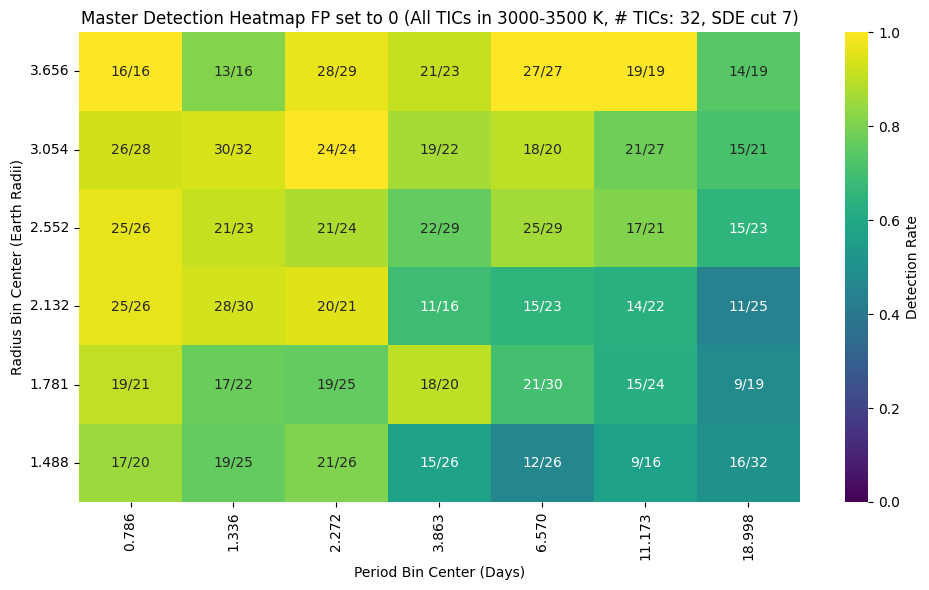

Removing 252 rows with missing stellar mass
Dataframe size after removal: 2787 rows
False positive cells: 48
[1.736848957477655, 2.021316889561047, 2.3523760949013375, 2.737657474907346, 3.1860417499398235, 3.707864159559684]
radius_centers: [1.736848957477655, 2.021316889561047, 2.3523760949013375, 2.737657474907346, 3.1860417499398235, 3.707864159559684]
heatmap index: [1.736848957477655, 2.021316889561047, 2.3523760949013375, 2.737657474907346, 3.1860417499398235, 3.707864159559684]


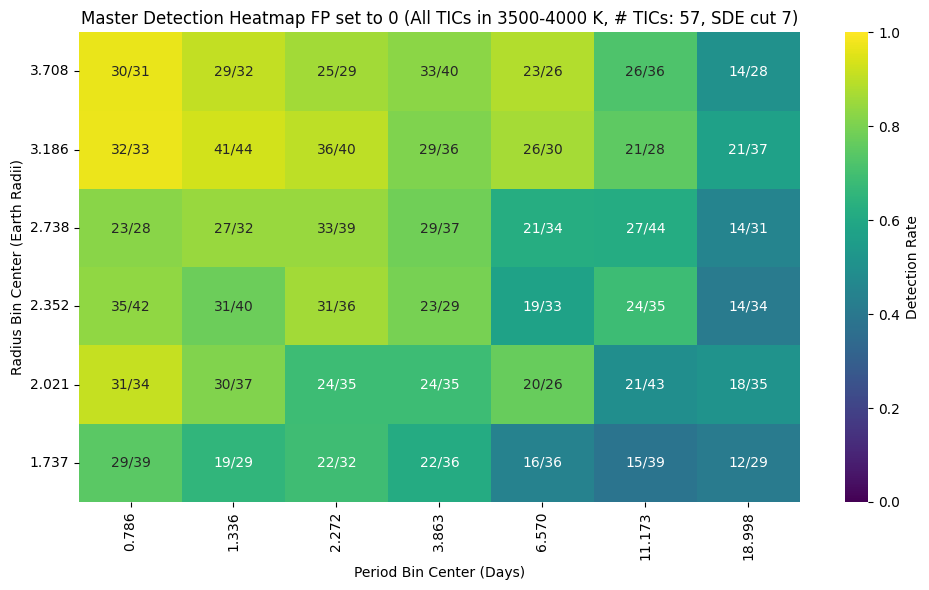

Removing 168 rows with missing stellar mass
Dataframe size after removal: 2344 rows
False positive cells: 39
[1.8256457503063668, 2.105482755934563, 2.4282134881829496, 2.8004127450459437, 3.2296631168473655, 3.7247094617665413]
radius_centers: [1.8256457503063668, 2.105482755934563, 2.4282134881829496, 2.8004127450459437, 3.2296631168473655, 3.7247094617665413]
heatmap index: [1.8256457503063668, 2.105482755934563, 2.4282134881829496, 2.8004127450459437, 3.2296631168473655, 3.7247094617665413]


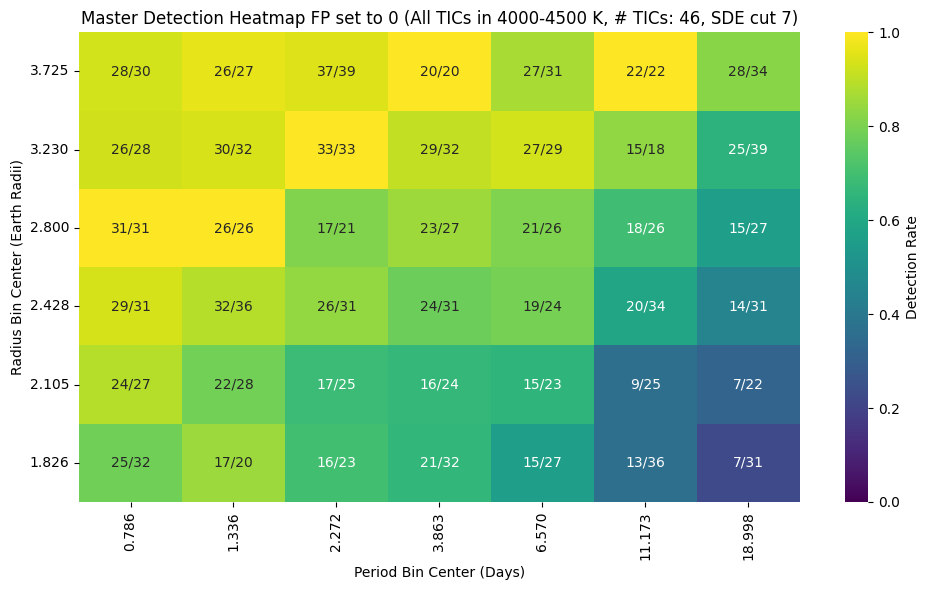

Removing 9 rows with missing stellar mass
Dataframe size after removal: 3230 rows
False positive cells: 44
[1.874806902965779, 2.1517585353294253, 2.4696222245814647, 2.8344416122940888, 3.2531531233955713, 3.733717850583235]
radius_centers: [1.874806902965779, 2.1517585353294253, 2.4696222245814647, 2.8344416122940888, 3.2531531233955713, 3.733717850583235]
heatmap index: [1.874806902965779, 2.1517585353294253, 2.4696222245814647, 2.8344416122940888, 3.2531531233955713, 3.733717850583235]


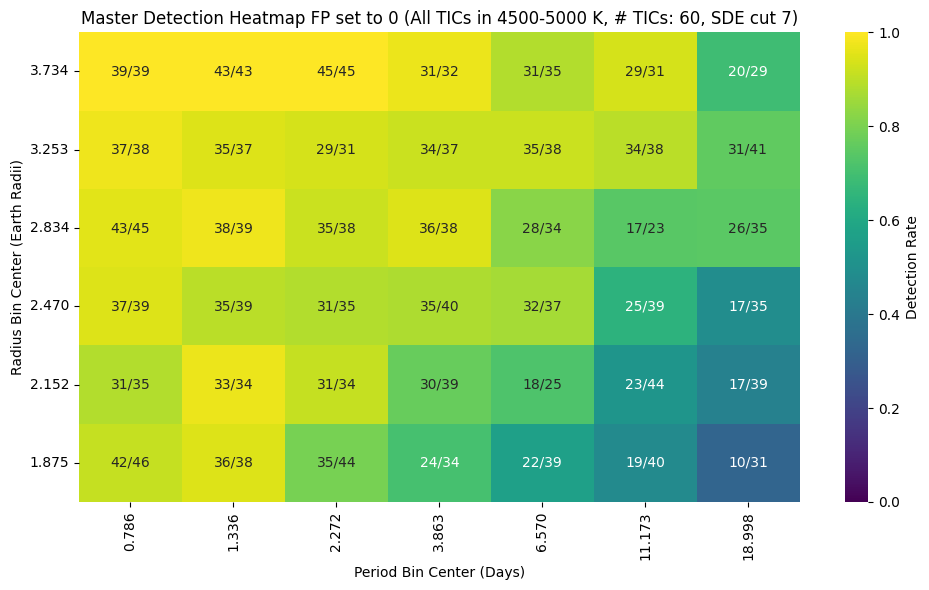

Removing 252 rows with missing stellar mass
Dataframe size after removal: 4981 rows
False positive cells: 73
[1.9238511279419546, 2.1977049008908236, 2.510540842402059, 2.8679079337785707, 3.2761450352508805, 3.7424933226003936]
radius_centers: [1.9238511279419546, 2.1977049008908236, 2.510540842402059, 2.8679079337785707, 3.2761450352508805, 3.7424933226003936]
heatmap index: [1.9238511279419546, 2.1977049008908236, 2.510540842402059, 2.8679079337785707, 3.2761450352508805, 3.7424933226003936]


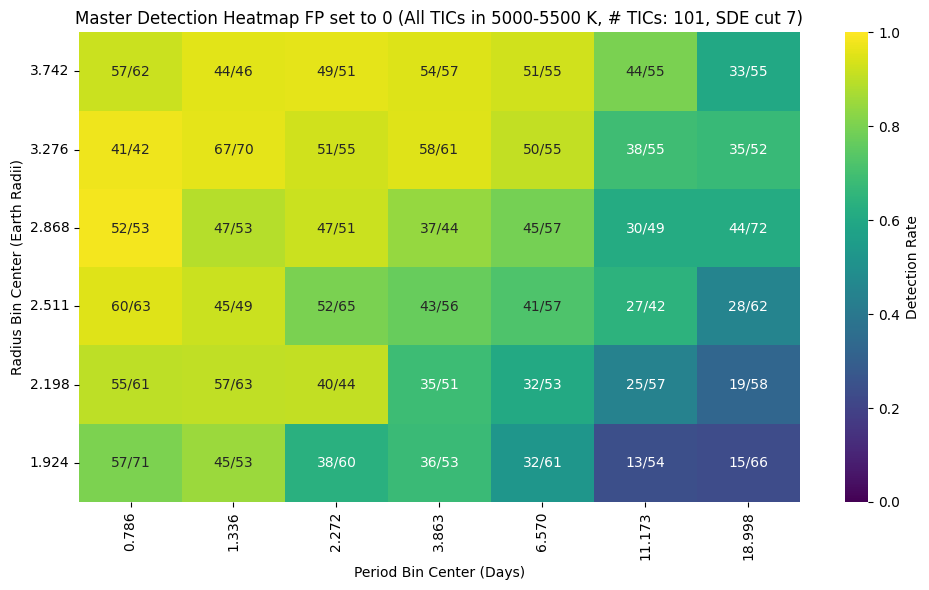

Removing 336 rows with missing stellar mass
Dataframe size after removal: 7385 rows
False positive cells: 113
[1.9825547890896862, 2.252421717014542, 2.5590231448827967, 2.9073594019177, 3.3031114661162566, 3.752733614699328]
radius_centers: [1.9825547890896862, 2.252421717014542, 2.5590231448827967, 2.9073594019177, 3.3031114661162566, 3.752733614699328]
heatmap index: [1.9825547890896862, 2.252421717014542, 2.5590231448827967, 2.9073594019177, 3.3031114661162566, 3.752733614699328]


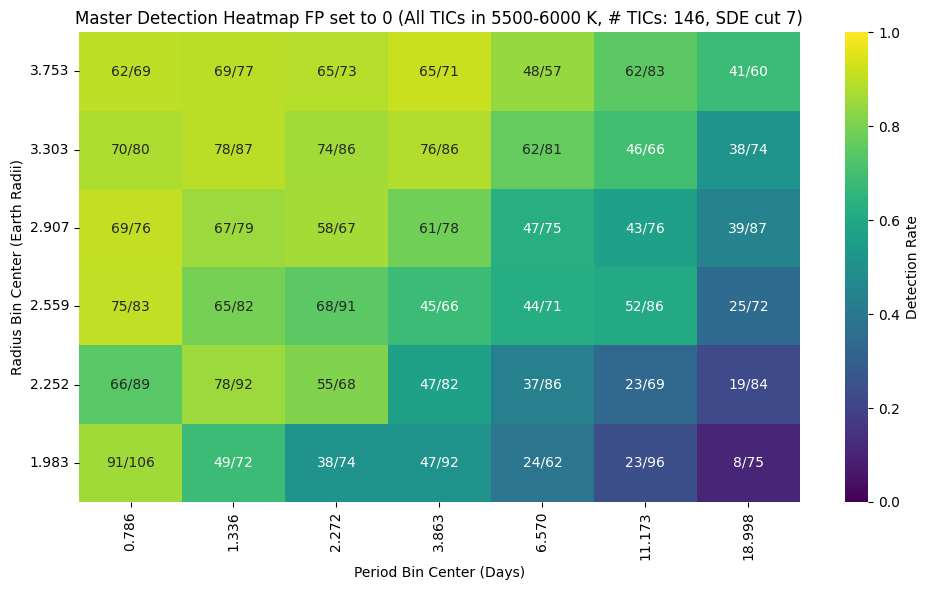

Removing 294 rows with missing stellar mass
Dataframe size after removal: 3978 rows
False positive cells: 41
[2.06058207879959, 2.3246966794718484, 2.6226641040650556, 2.95882342995133, 3.3380698946767566, 3.765926181654775]
radius_centers: [2.06058207879959, 2.3246966794718484, 2.6226641040650556, 2.95882342995133, 3.3380698946767566, 3.765926181654775]
heatmap index: [2.06058207879959, 2.3246966794718484, 2.6226641040650556, 2.95882342995133, 3.3380698946767566, 3.765926181654775]


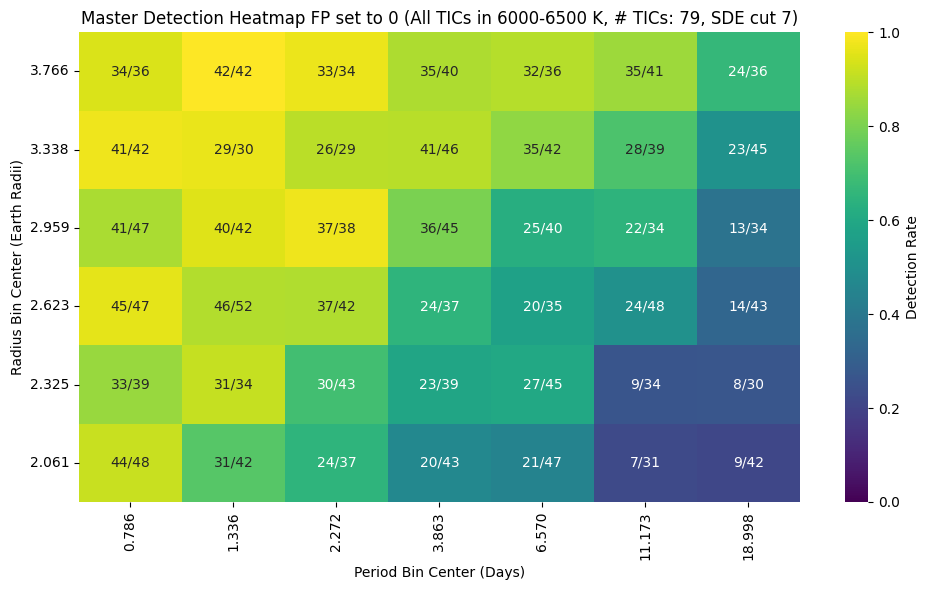

Removing 126 rows with missing stellar mass
Dataframe size after removal: 1512 rows
False positive cells: 27
[2.138341614734861, 2.396230131484655, 2.6852205482363596, 3.009063819844112, 3.3719632742426953, 3.7786291695968606]
radius_centers: [2.138341614734861, 2.396230131484655, 2.6852205482363596, 3.009063819844112, 3.3719632742426953, 3.7786291695968606]
heatmap index: [2.138341614734861, 2.396230131484655, 2.6852205482363596, 3.009063819844112, 3.3719632742426953, 3.7786291695968606]


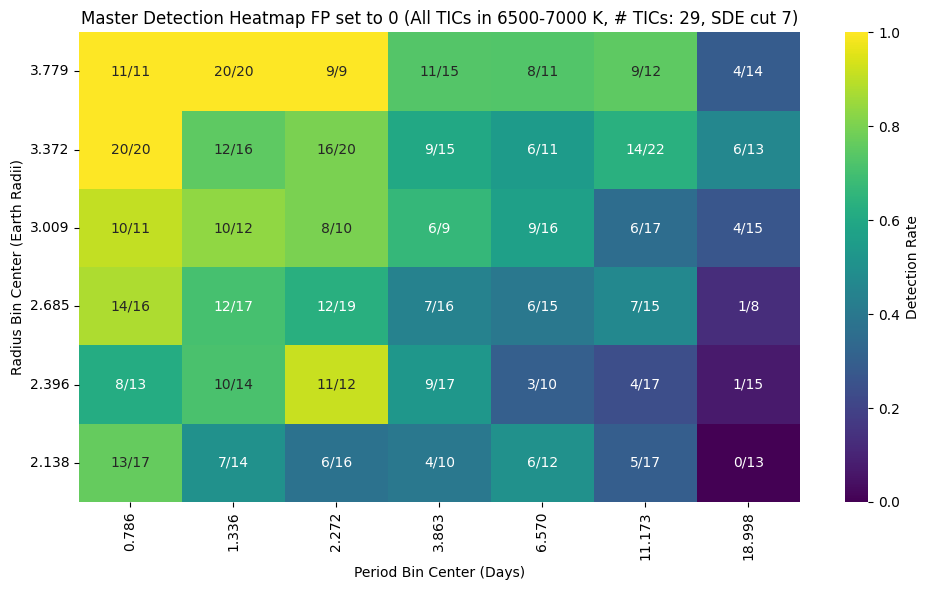

In [14]:
import os
import glob
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib.pyplot as plt
from scipy.interpolate import griddata

def calc_geometric_transit_probability(df):
    # Cross-match with CTL.csv to add stellar mass
    ctl_df = pd.read_csv('./take_two_stellar_params_CTL.csv')
    df = df.copy()

    # Clean TIC column in both dataframes to ensure matching
    df['TIC_clean'] = df['TIC'].str.replace('TIC ', '')
    ctl_df['TIC_clean'] = ctl_df['id'].astype(str).str.replace('TIC ', '')

    # Merge to add stellar mass
    df = df.merge(
        ctl_df[['TIC_clean', 'MASS']], 
        on='TIC_clean', 
        how='left'
    ).rename(columns={'MASS': 'Stellar Mass'})

    # Drop the temporary TIC_clean column
    df = df.drop('TIC_clean', axis=1)
    #print(df)


    # Check for missing stellar masses and remove them
    missing_mass = df['Stellar Mass'].isna().sum()
    print(f"Removing {missing_mass} rows with missing stellar mass")
    df = df.dropna(subset=['Stellar Mass'])
    print(f"Dataframe size after removal: {len(df)} rows")

    # Calculate transit probability using actual stellar mass (vectorized)
    R_star = df['Stellar Radius'] * 6.96e8  # Solar radii to meters
    R_planet = df['True Radius (Earth Radii)'] * 6.378e6  # Earth radii to meters
    P = df['True Period (Days)'] * 86400  # Days to seconds
    M_star = df['Stellar Mass'] * 1.989e30  # Solar masses to kg
    G = 6.67430e-11  # Gravitational constant in m³/(kg·s²)

    a = ((P**2 * G * M_star) / (4 * np.pi**2))**(1/3)  # Semi-major axis in meters
    df['Transit Probability'] = (R_star + R_planet) / a
    return df


def transit_probability_heatmap(df, temp_range, periods_bins, radii_bins):
    # temp_range should be like (3000, 3500)
    temp_min, temp_max = temp_range

    # Filter based on Stellar Temperature
    temp_lim = (df['Stellar Temperature'] >= temp_min) & (df['Stellar Temperature'] <= temp_max)
    df = df[temp_lim].copy()

    #########################
    df = calc_geometric_transit_probability(df)
    ########################

    unique_tics = df['TIC'].unique()

    # Calculate bin centers for labeling
    radius_centers = [10**((np.log10(rmin) + np.log10(rmax))/2) for rmin, rmax in radii_bins]
    period_centers = [10**((np.log10(pmin) + np.log10(pmax))/2) for pmin, pmax in periods_bins]

    # Collect all transit probability results here
    all_transit_rows = []

    for tic in unique_tics:
        try:
            tic_rows = df[df['TIC'] == tic]
            if tic_rows['True Radius (Earth Radii)'].isnull().all():
                continue

            for _, row in tic_rows.iterrows():
                true_period = float(row['True Period (Days)'])
                true_radius = float(row['True Radius (Earth Radii)'])
                
                # Find which bin this period and radius fall into
                period_bin_center = None
                for i, (pmin, pmax) in enumerate(periods_bins):
                    if pmin <= true_period < pmax:
                        period_bin_center = period_centers[i]
                        break
                
                radius_bin_center = None
                for i, (rmin, rmax) in enumerate(radii_bins):
                    if rmin <= true_radius < rmax:
                        radius_bin_center = radius_centers[i]
                        break
                
                # Skip if outside bin ranges
                if period_bin_center is None or radius_bin_center is None:
                    continue

                all_transit_rows.append({
                    'radius_bin_center': radius_bin_center,
                    'period_bin_center': period_bin_center,
                    'Transit Probability': row['Transit Probability']
                })

        except Exception as e:
            print(f"An error for TIC {tic} occurred: {e}")
            continue

    if all_transit_rows:
        transit_df = pd.DataFrame(all_transit_rows)

        # Group by bin centers, average transit probabilities
        transit_counts = transit_df.groupby(
            ['radius_bin_center', 'period_bin_center']
        ).agg(
            avg_transit_prob=('Transit Probability', 'mean'),
            count=('Transit Probability', 'count')
        ).reset_index()

        # Pivot for heatmap
        transit_pivot = transit_counts.pivot(
            index='radius_bin_center',
            columns='period_bin_center',
            values='avg_transit_prob'
        )

        # Create annotation matrix showing transit probability values
        annot_matrix = transit_counts.pivot(
            index='radius_bin_center',
            columns='period_bin_center',
            values='avg_transit_prob'
        ).round(4)  # Round to 4 decimal places for readability

        plt.figure(figsize=(10, 6))
        sns.heatmap(
            transit_pivot,
            annot=annot_matrix,
            fmt='.4f',  # Display transit probability values with 4 decimal places
            cmap='plasma',
            cbar_kws={'label': 'Average Transit Probability'},
            vmin=0, vmax=transit_pivot.max().max()
        )
        plt.gca().invert_yaxis()
        
        # Format axis labels to 3 decimal places
        ax = plt.gca()
        ax.set_xticklabels([f'{float(label.get_text()):.3f}' if label.get_text() else '' 
                           for label in ax.get_xticklabels()])
        ax.set_yticklabels([f'{float(label.get_text()):.3f}' if label.get_text() else '' 
                           for label in ax.get_yticklabels()])
        
        plt.title(f'Transit Probability Heatmap ({temp_min}-{temp_max} K, # TICs: {len(unique_tics)})')
        plt.xlabel('Period Bin Center (Days)')
        plt.ylabel('Radius Bin Center (Earth Radii)')
        plt.tight_layout()
        plt.show()

        # output_dir = './master_heatmaps/'
        # os.makedirs(output_dir, exist_ok=True)
        # output_filename = f'geometry_heatmap_{temp_min}_{temp_max}_K_tics_{len(unique_tics)}.csv'
        # transit_counts.to_csv(os.path.join(output_dir, output_filename), index=False)

    else:
        print("No valid data to generate transit probability heatmap.")

def filter_out_false_positives(df, sde_threshold):
    false_positive_df = pd.read_csv('/Users/danayaptangco/local_code/Mulders/main_proj/tess_demographics/gen_heatmaps/rec_only/rec_results/take_two_CTL_TLS_recovery.csv')

    rows_to_keep = []
    false_positive_count = 0


    for idx, row in df.iterrows():
        tic = row['TIC']
        true_period = float(row['True Period (Days)'])
        
        # Check if this TIC exists in false positives data
        fp_row = false_positive_df[false_positive_df['TIC'] == tic]
        
        is_false_positive = False
        
        # If we found matching TIC in false positive data
        if len(fp_row) > 0:
            try:
                # Parse false positive periods and SDE arrays
                fp_periods = fp_row['TLS Periods array'].iloc[0].replace('[', '').replace(']', '').split()
                fp_periods = [float(p) for p in fp_periods]
                fp_sde = fp_row['TLS SDE > 7 array'].iloc[0].replace('[', '').replace(']', '').split()
                fp_sde = [float(s) for s in fp_sde]
                
                # Get periods above threshold from false positives
                fp_periods_above_threshold = [p for p, s in zip(fp_periods, fp_sde) if s > sde_threshold]
                
                # Check if any false positive periods match our true period or its aliases
                aliases = [true_period, true_period/2, true_period*2, true_period/3, true_period*3]
                is_false_positive = any(0.999 * alias < fp_p < 1.001 * alias 
                                    for fp_p in fp_periods_above_threshold 
                                    for alias in aliases)

                # SET TO 0 method
                if any(any(0.999 * alias < fp_p < 1.001 * alias for alias in aliases) for fp_p in fp_periods_above_threshold):
                    df.loc[idx, 'TLS Periods array'] = '[]'
                    df.loc[idx, 'TLS SDE > 7 array'] = '[]'
                    false_positive_count +=1
                #print(f"TIC {tic}: is_false_positive = {is_false_positive}")
            except:
                pass
        
        # Keep the row only if it's NOT a false positive
        if is_false_positive == False:
            rows_to_keep.append(idx)

            ##SET TO 0 method
        elif is_false_positive == True:
            rows_to_keep.append(idx)



    # Filter the dataframe
    df_filtered = df.loc[rows_to_keep].reset_index(drop=True)

    #print(f"Original rows: {len(df)}")
    #print(f"Rows after filtering false positives: {len(df_filtered)}")
    print(f"False positive cells: {false_positive_count}")

    # Replace df with the filtered version
    return df_filtered

def master_heatmap(df, sde_threshold, temp_range, periods_bins, radii_bins):
    # temp_range should be like "3000-3500" or (3000, 3500)
    temp_min, temp_max = temp_range

    # Filter based on Stellar Temperature
    temp_lim = (df['Stellar Temperature'] >= temp_min) & (df['Stellar Temperature'] <= temp_max)
    df = df[temp_lim].copy()

    #########################
    #this removes rows with missing stellar mass
    df = calc_geometric_transit_probability(df)

    df = filter_out_false_positives(df, sde_threshold)
    ########################

    unique_tics = df['TIC'].unique()
    #print(len(unique_tics))

    '''   Temperature    Radius
    0       3250.0  1.360449
    1       3750.0  1.611302
    2       4250.0  1.702586
    3       4750.0  1.749562
    4       5250.0  1.806242
    5       5750.0  1.860371
    6       6250.0  1.942204
    7       6750.0  2.024992 
    '''


    # Calculate bin centers for labeling
    if temp_range == (3000, 3500):
        radius_bin_edges = np.logspace(np.log10(1.36), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
    elif temp_range == (3500, 4000):
        radius_bin_edges = np.logspace(np.log10(1.61), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
    elif temp_range == (4000, 4500):
        radius_bin_edges = np.logspace(np.log10(1.70), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
    elif temp_range == (4500, 5000):
        radius_bin_edges = np.logspace(np.log10(1.75), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
    elif temp_range == (5000, 5500):
        radius_bin_edges = np.logspace(np.log10(1.80), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
    elif temp_range == (5500, 6000):
        radius_bin_edges = np.logspace(np.log10(1.86), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
    elif temp_range == (6000, 6500):
        radius_bin_edges = np.logspace(np.log10(1.94), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
    elif temp_range == (6500, 7000):
        radius_bin_edges = np.logspace(np.log10(2.02), np.log10(4.0), num=7)
        radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]

    
    radius_centers = [10**((np.log10(rmin) + np.log10(rmax))/2) for rmin, rmax in radii_bins]
    print(radius_centers)
    period_centers = [10**((np.log10(pmin) + np.log10(pmax))/2) for pmin, pmax in periods_bins]






    # Collect all detection results here
    all_heatmap_rows = []

    for tic in unique_tics:
        try:
            tic_rows = df[df['TIC'] == tic]
            if tic_rows['True Radius (Earth Radii)'].isnull().all():
                print(f"No valid data for {tic}, skipping...")
                continue

            for _, row in tic_rows.iterrows():
                true_period = float(row['True Period (Days)'])
                true_radius = float(row['True Radius (Earth Radii)'])
                
                # Find which bin this period and radius fall into
                period_bin_center = None
                for i, (pmin, pmax) in enumerate(periods_bins):
                    if pmin <= true_period < pmax:
                        period_bin_center = period_centers[i]
                        break
                
                radius_bin_center = None
                for i, (rmin, rmax) in enumerate(radii_bins):
                    if rmin <= true_radius < rmax:
                        radius_bin_center = radius_centers[i]
                        break
                
                # Skip if outside bin ranges
                if period_bin_center is None or radius_bin_center is None:
                    continue

                try:
                    periods = row['TLS Periods array'].replace('[', '').replace(']', '').split()
                    sdes = row['TLS SDE > 7 array'].replace('[', '').replace(']', '').split()
                    periods = [float(p) for p in periods]
                    sdes = [float(s) for s in sdes]
                except:
                    continue

                # Periods with SDE above threshold
                periods_above_threshold = [
                    p for p, s in zip(periods, sdes) if s > sde_threshold
                ]
                # Include aliases (harmonics) for detection check
                aliases = [true_period, true_period / 2, true_period * 2, true_period / 3, true_period * 3]

                detected = any(
                    0.999 * alias < p < 1.001 * alias
                    for alias in aliases
                    for p in periods_above_threshold
                )
                #print(radius_bin_center)
                all_heatmap_rows.append({
                    'radius_bin_center': radius_bin_center,
                    'period_bin_center': period_bin_center,
                    'Detection': int(detected),
                    'Transit Probability': row['Transit Probability']
                })
                #print(all_heatmap_rows)

        except Exception as e:
            print(f"An error for TIC {tic} occurred: {e}")
            continue

    if all_heatmap_rows:
        heatmap_df = pd.DataFrame(all_heatmap_rows)
        heatmap_df['Detection'] = pd.to_numeric(heatmap_df['Detection'])

        # Group by bin centers, count detections and trials
        heatmap_counts = heatmap_df.groupby(
            ['radius_bin_center', 'period_bin_center']
        ).agg(
            detections=('Detection', 'sum'),
            trials=('Detection', 'count'),
            transit_prob=('Transit Probability', 'mean')
        ).reset_index()

        # Calculate detection rate for coloring
        heatmap_counts['detection_rate'] = heatmap_counts['detections'] / heatmap_counts['trials']
        
        # Pivot for heatmap coloring
        heatmap_pivot = heatmap_counts.pivot(
            index='radius_bin_center',
            columns='period_bin_center',
            values='detection_rate'
        )

        # Create annotation matrix as "detections/trials"
        annot_matrix = heatmap_counts.pivot(
            index='radius_bin_center',
            columns='period_bin_center',
            values='detections'
        ).astype(str) + "/" + heatmap_counts.pivot(
            index='radius_bin_center',
            columns='period_bin_center',
            values='trials'
        ).astype(str)

        plt.figure(figsize=(10, 6))
        sns.heatmap(
            heatmap_pivot,
            annot=annot_matrix,
            fmt='',  # Display annotations as given
            cmap='viridis',
            cbar_kws={'label': 'Detection Rate'},
            vmin=0, vmax=1
        )
        
        plt.gca().invert_yaxis()

        print("radius_centers:", radius_centers)
        print("heatmap index:", heatmap_pivot.index.tolist())
        
        # Format axis labels to 3 decimal places
        ax = plt.gca()
        ax.set_xticklabels([f'{float(label.get_text()):.3f}' if label.get_text() else '' 
                           for label in ax.get_xticklabels()])
        ax.set_yticklabels([f'{float(label.get_text()):.3f}' if label.get_text() else '' 
                           for label in ax.get_yticklabels()])
        
        plt.title(f'Master Detection Heatmap FP set to 0 (All TICs in {temp_min}-{temp_max} K, # TICs: {len(unique_tics)}, SDE cut {sde_threshold})')
        plt.xlabel('Period Bin Center (Days)')
        plt.ylabel('Radius Bin Center (Earth Radii)')
        plt.tight_layout()
        plt.show()

        #save to csv
        output_dir = './take_two_master_heatmaps_empirical_radius/'
        os.makedirs(output_dir, exist_ok=True)
        output_filename = f'master_heatmap_{temp_min}_{temp_max}_K_sde_{sde_threshold}.csv'
        heatmap_counts.to_csv(os.path.join(output_dir, output_filename), index=False)

    else:
        print("No valid data to generate master heatmap.")

#######################
#Binning
# Radius bin edges fixed from 1.8 to 4.0 (inclusive), log-spaced
radius_bin_edges = np.logspace(np.log10(1.8), np.log10(4.0), num=7)
radii_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]
# Radius bin centers from bin edges (geometric centers)
radii_centers = [float(f"{np.sqrt(radius_bin_edges[i] * radius_bin_edges[i+1]):.3f}") for i in range(len(radius_bin_edges)-1)]
# Log-spaced list between 0.7 and 25 (inclusive), in log10 space
periods_centers = np.logspace(np.log10(0.78555), np.log10(19), num=7) #down to .6
#periods_centers = np.logspace(np.log10(0.7), np.log10(19), num=7)


# Convert periods_centers to floats with up to 3 decimals
periods_centers = [float(f"{v:.3f}") for v in periods_centers]


# Generate bin edges from centers
periods_log = np.log10(periods_centers)
log_step = periods_log[1] - periods_log[0]
period_bin_edges = [10**(periods_log[0] - log_step/2)]


period_bin_edges.extend([10**((periods_log[i] + periods_log[i+1])/2) for i in range(len(periods_log)-1)])
period_bin_edges.append(10**(periods_log[-1] + log_step/2))
periods_bins = [(period_bin_edges[i], period_bin_edges[i+1]) for i in range(len(period_bin_edges)-1)]

# radii_bins already set from fixed 1.8-4.0 edges above


df = pd.read_csv("./take_two_tls_results_combined_rebalanced.csv")
df = df[['TIC', 'True Radius (Earth Radii)', 'True Period (Days)', 'TLS Periods array', 'TLS SDE > 7 array', 'Stellar Radius', 'Stellar Temperature']]
before = len(df)
df = df.drop_duplicates(subset=['TIC', 'True Radius (Earth Radii)', 'True Period (Days)'])
after = len(df)
print(f"Duplicates dropped: {before - after}")
print(f'Len of df after dropping duplicates: {len(df)}')

unique_tics = df['TIC'].unique()
print(f"Number of unique TICs: {len(unique_tics)}\n")

sde_threshold = 7
temp_ranges = [(3000, 3500), (3500, 4000), (4000, 4500), (4500, 5000), (5000, 5500), (5500, 6000), (6000, 6500), (6500, 7000)]#, (7000,8000)]
#temp_ranges = [(3000,7000)]
#temp_ranges = [(t, t + 1000) for t in range(3000, 7000, 1000)]

for temp_range in temp_ranges:
    master_heatmap(df, sde_threshold, temp_range, periods_bins=periods_bins, radii_bins=radii_bins)
    #transit_probability_heatmap(df, temp_range, periods_bins=periods_bins, radii_bins=radii_bins)


In [15]:
import glob, re, pandas as pd
allowed = set(pd.read_csv("rebalanced_matched_CTL_sample.csv")["tic"])
csv_files = glob.glob("./take_two_tls_results_per_tic_rebalanced/*.csv") + glob.glob("./take_two_tls_results_per_tic_unbalanced/*.csv")
csv_files = [f for f in csv_files if int(re.search(r"TIC_(\d+)_", f).group(1)) in allowed]
combined_df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
combined_df.to_csv("take_two_tls_results_combined_rebalanced.csv", index=False)
print(len(combined_df['TIC'].unique()), "tics in combined dataframe")

#print how many tics came from unbalanced vs rebalanced 


621 tics in combined dataframe


In [16]:
import glob
import re
import pandas as pd

allowed = set(pd.read_csv("rebalanced_matched_CTL_sample.csv")["tic"])

rebalanced_files = glob.glob("./take_two_tls_results_per_tic_rebalanced/*.csv")
unbalanced_files = glob.glob("./take_two_tls_results_per_tic_unbalanced/*.csv")

rebalanced_files = [
    f for f in rebalanced_files
    if int(re.search(r"TIC_(\d+)_", f).group(1)) in allowed
]

unbalanced_files = [
    f for f in unbalanced_files
    if int(re.search(r"TIC_(\d+)_", f).group(1)) in allowed
]

dfs = []

for f in rebalanced_files:
    df = pd.read_csv(f)
    df["source"] = "rebalanced"
    dfs.append(df)

for f in unbalanced_files:
    df = pd.read_csv(f)
    df["source"] = "unbalanced"
    dfs.append(df)

combined_df = pd.concat(dfs, ignore_index=True)
combined_df.to_csv("take_two_tls_results_combined_rebalanced.csv", index=False)

print(f"{combined_df['TIC'].nunique()} unique TICs in combined dataframe")

print("\nUnique TICs by source:")
print(combined_df.groupby("source")["TIC"].nunique())

print("\nRows by source:")
print(combined_df["source"].value_counts())

621 unique TICs in combined dataframe

Unique TICs by source:
source
rebalanced     72
unbalanced    549
Name: TIC, dtype: int64

Rows by source:
source
unbalanced    27750
rebalanced     3024
Name: count, dtype: int64


In [17]:
already_run = set(
    pd.read_csv("rebalanced_matched_CTL_sample.csv")
    .query("source == 'already_run'")["tic"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

present = set(
    combined_df.loc[combined_df["source"] == "unbalanced", "TIC"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

missing = sorted(already_run - present)

print(len(missing), "missing TICs")
print(missing)

51 missing TICs
[22211541, 22741629, 24250831, 36876239, 37002043, 37593427, 41030435, 41789492, 140578481, 155896956, 198010547, 209428610, 220433100, 220561236, 229406743, 229583294, 229675482, 230073588, 230083056, 230086327, 230088977, 230239007, 230286926, 238876808, 240004851, 242990547, 243333942, 264899051, 267602391, 267757864, 268529531, 269894504, 308599430, 309249660, 309350543, 309756397, 309778333, 310845943, 311407379, 311430661, 314976957, 337025463, 369472669, 369984053, 370883476, 371330650, 371426141, 372943067, 376851872, 392963260, 457088541]
